In [1]:
# N-CMAPSS DS02-006 Pure Transformer Baseline
import os, time, math, random, h5py
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm

SEED=42
FILE_PATH='N-CMAPSS_DS02-006.h5'
WINDOW_SIZE=50
INPUT_SIZE=18
D_MODEL=32
N_HEAD=2
N_LAYERS=2
DIM_FEEDFORWARD=64
DROPOUT=0.10
BATCH_SIZE=1024
LEARNING_RATE=3e-4
WEIGHT_DECAY=1e-4
MAX_EPOCHS=80
PATIENCE=12
GRAD_CLIP=1.0
MODEL_NAME='transformer_baseline'
MODEL_SAVE_PATH=f'best_{MODEL_NAME}.pth'
RESULT_FIG_PATH=f'{MODEL_NAME}_results.png'
NUM_WORKERS=0

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    if torch.cuda.is_available():
        torch.backends.cudnn.deterministic=True; torch.backends.cudnn.benchmark=False
set_seed(SEED)

def load_ncmaps(file_path):
    if not os.path.exists(file_path): raise FileNotFoundError(f'找不到数据文件：{file_path}\n当前工作目录：{os.getcwd()}')
    with h5py.File(file_path,'r') as f:
        W_dev=f['W_dev'][:]; Xs_dev=f['X_s_dev'][:]; A_dev=f['A_dev'][:]; Y_dev=f['Y_dev'][:]
        W_test=f['W_test'][:]; Xs_test=f['X_s_test'][:]; A_test=f['A_test'][:]; Y_test=f['Y_test'][:]
    X_dev=np.concatenate([W_dev,Xs_dev],axis=1).astype(np.float32)
    X_test=np.concatenate([W_test,Xs_test],axis=1).astype(np.float32)
    return X_dev,np.asarray(Y_dev,dtype=np.float32).reshape(-1),A_dev[:,0].astype(np.int64),X_test,np.asarray(Y_test,dtype=np.float32).reshape(-1),A_test[:,0].astype(np.int64)

def split_by_unit(X,Y,units):
    units_unique=np.unique(units)
    if len(units_unique)<2: raise ValueError('开发集中的发动机数量不足，无法划分验证集。')
    val_unit=units_unique[-1]; train_units=units_unique[:-1]
    tm=np.isin(units,train_units); vm=units==val_unit
    return X[tm],Y[tm],units[tm],X[vm],Y[vm],units[vm],train_units,val_unit

class MinMaxScaler2:
    def __init__(self): self.x_min=None; self.x_max=None
    def fit(self,x):
        self.x_min=np.nanmin(x,axis=0).astype(np.float32); self.x_max=np.nanmax(x,axis=0).astype(np.float32)
    def transform(self,x):
        if self.x_min is None: raise RuntimeError('Scaler 尚未 fit。')
        d=np.where(self.x_max-self.x_min<1e-8,1.0,self.x_max-self.x_min)
        return (2.0*(x-self.x_min)/d-1.0).astype(np.float32)

class NCMAPSSDataset(Dataset):
    def __init__(self,X,Y,unit_array,window_size=50):
        self.X=torch.from_numpy(np.asarray(X,dtype=np.float32)); self.Y=torch.from_numpy(np.asarray(Y,dtype=np.float32).reshape(-1,1)); self.unit=np.asarray(unit_array); self.window_size=window_size
        starts=[]
        for u in np.unique(self.unit):
            idx=np.where(self.unit==u)[0]
            starts.extend(idx[:max(0,len(idx)-window_size+1)])
        self.valid_indices=np.asarray(starts,dtype=np.int64)
    def __len__(self): return len(self.valid_indices)
    def __getitem__(self,i):
        s=int(self.valid_indices[i]); e=s+self.window_size
        return self.X[s:e],self.Y[e-1]

class PositionalEncoding(nn.Module):
    def __init__(self,d_model,max_len=512):
        super().__init__(); pe=torch.zeros(max_len,d_model); pos=torch.arange(max_len,dtype=torch.float32).unsqueeze(1)
        div=torch.exp(torch.arange(0,d_model,2,dtype=torch.float32)*(-math.log(10000.0)/d_model))
        pe[:,0::2]=torch.sin(pos*div); pe[:,1::2]=torch.cos(pos*div); self.register_buffer('pe',pe.unsqueeze(0))
    def forward(self,x): return x+self.pe[:,:x.size(1),:]

class TransformerBaseline(nn.Module):
    def __init__(self,input_size=18,d_model=32,nhead=2,num_layers=2,dim_feedforward=64,dropout=.1,window_size=50):
        super().__init__()
        if d_model%nhead: raise ValueError('d_model 必须能被 nhead 整除')
        self.input_projection=nn.Sequential(nn.Linear(input_size,d_model),nn.LayerNorm(d_model))
        self.pos_encoder=PositionalEncoding(d_model,window_size)
        layer=nn.TransformerEncoderLayer(d_model=d_model,nhead=nhead,dim_feedforward=dim_feedforward,dropout=dropout,activation='gelu',batch_first=True,norm_first=True)
        self.encoder=nn.TransformerEncoder(layer,num_layers=num_layers,norm=nn.LayerNorm(d_model))
        self.regressor=nn.Sequential(nn.Linear(d_model,32),nn.GELU(),nn.Dropout(dropout),nn.Linear(32,1))
        self._init()
    def _init(self):
        for m in self.modules():
            if isinstance(m,nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None: nn.init.zeros_(m.bias)
    def forward(self,x):
        x=self.input_projection(x); x=self.pos_encoder(x); x=self.encoder(x); return self.regressor(x[:,-1,:])

def rmse_np(p,y): return float(np.sqrt(np.mean((np.asarray(p).reshape(-1)-np.asarray(y).reshape(-1))**2)))
def mae_np(p,y): return float(np.mean(np.abs(np.asarray(p).reshape(-1)-np.asarray(y).reshape(-1))))

def train_one_epoch(model,loader,criterion,opt,device):
    model.train(); total=0.0
    for xb,yb in loader:
        xb=xb.to(device,non_blocking=True); yb=yb.to(device,non_blocking=True); opt.zero_grad(set_to_none=True)
        loss=criterion(model(xb),yb); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),GRAD_CLIP); opt.step(); total+=loss.item()
    return total/max(len(loader),1)

@torch.no_grad()
def validate(model,loader,criterion,device):
    model.eval(); total=0.0
    for xb,yb in loader:
        xb=xb.to(device,non_blocking=True); yb=yb.to(device,non_blocking=True); total+=criterion(model(xb),yb).item()
    return total/max(len(loader),1)

@torch.no_grad()
def predict(model,loader,device):
    model.eval(); ps=[]; ys=[]
    for xb,yb in tqdm(loader,desc='Testing',ncols=100):
        ps.append(model(xb.to(device,non_blocking=True)).cpu().numpy()); ys.append(yb.numpy())
    return np.concatenate(ps).reshape(-1),np.concatenate(ys).reshape(-1)

def main():
    print('='*72); print('N-CMAPSS DS02-006 | Pure Transformer Baseline'); print('='*72)
    device=torch.device('cuda' if torch.cuda.is_available() else 'cpu'); print('Device:',device)
    if torch.cuda.is_available(): print('GPU:',torch.cuda.get_device_name(0))
    Xd,Yd,ud,Xt,Yt,ut=load_ncmaps(FILE_PATH); print('Dev shape:',Xd.shape,'Test shape:',Xt.shape)
    Xtr,Ytr,utr,Xv,Yv,uv,train_units,val_unit=split_by_unit(Xd,Yd,ud)
    print('Train engines:',train_units); print('Validation engine:',val_unit)
    scaler=MinMaxScaler2(); scaler.fit(Xtr); Xtr=scaler.transform(Xtr); Xv=scaler.transform(Xv); Xt=scaler.transform(Xt)
    tr_ds=NCMAPSSDataset(Xtr,Ytr,utr,WINDOW_SIZE); va_ds=NCMAPSSDataset(Xv,Yv,uv,WINDOW_SIZE); te_ds=NCMAPSSDataset(Xt,Yt,ut,WINDOW_SIZE)
    print(f'Train windows: {len(tr_ds):,}'); print(f'Val windows: {len(va_ds):,}'); print(f'Test windows: {len(te_ds):,}')
    pin=torch.cuda.is_available()
    tr=DataLoader(tr_ds,batch_size=BATCH_SIZE,shuffle=True,drop_last=True,num_workers=NUM_WORKERS,pin_memory=pin)
    va=DataLoader(va_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS,pin_memory=pin)
    te=DataLoader(te_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS,pin_memory=pin)
    model=TransformerBaseline(INPUT_SIZE,D_MODEL,N_HEAD,N_LAYERS,DIM_FEEDFORWARD,DROPOUT,WINDOW_SIZE).to(device)
    params=sum(p.numel() for p in model.parameters() if p.requires_grad); print('Trainable params:',f'{params:,}')
    criterion=nn.MSELoss(); opt=torch.optim.AdamW(model.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
    scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode='min',factor=.5,patience=3,min_lr=1e-6)
    best=float('inf'); bad=0; train_losses=[]; val_losses=[]; start=time.time()
    for epoch in range(1,MAX_EPOCHS+1):
        t=time.time(); tl=train_one_epoch(model,tr,criterion,opt,device); vl=validate(model,va,criterion,device); scheduler.step(vl); lr=opt.param_groups[0]['lr']; train_losses.append(tl); val_losses.append(vl)
        print(f'Epoch {epoch:03d}/{MAX_EPOCHS} | Train={tl:.6f} | Val={vl:.6f} | LR={lr:.2e} | {time.time()-t:.1f}s')
        if vl<best:
            best=vl; bad=0; torch.save({'model_state_dict':model.state_dict(),'input_size':INPUT_SIZE,'d_model':D_MODEL,'nhead':N_HEAD,'num_layers':N_LAYERS,'dim_feedforward':DIM_FEEDFORWARD,'dropout':DROPOUT,'window_size':WINDOW_SIZE,'best_val_loss':best,'x_min':scaler.x_min,'x_max':scaler.x_max},MODEL_SAVE_PATH); print('  -> Best checkpoint saved.')
        else:
            bad+=1; print(f'  -> No improvement: {bad}/{PATIENCE}')
            if bad>=PATIENCE: print('Early stopping.'); break
    print(f'Training finished: {(time.time()-start)/60:.2f} min; Best Val MSE={best:.6f}')
    ck=torch.load(MODEL_SAVE_PATH,map_location=device); model.load_state_dict(ck['model_state_dict']); p,y=predict(model,te,device); rmse=rmse_np(p,y); mae=mae_np(p,y)
    print('\n'+'='*72); print('TEST RESULT'); print('='*72); print(f'Test RMSE: {rmse:.6f}'); print(f'Test MAE : {mae:.6f}')
    labels=np.array([ut[int(s)] for s in te_ds.valid_indices]); unit_rmses=[]; names=[]; print('\nPer-engine RMSE:')
    for u in np.unique(labels):
        m=labels==u; r=rmse_np(p[m],y[m]); a=mae_np(p[m],y[m]); unit_rmses.append(r); names.append(str(u)); print(f' Unit {int(u):3d}: RMSE={r:.6f}, MAE={a:.6f}, N={int(m.sum()):,}')
    fig=plt.figure(figsize=(14,10)); ax=fig.add_subplot(2,2,1); ax.plot(train_losses,label='Train Loss'); ax.plot(val_losses,label='Val Loss'); ax.set_title('Transformer Baseline Training Curve'); ax.set_xlabel('Epoch'); ax.set_ylabel('MSE'); ax.grid(alpha=.3); ax.legend()
    ax=fig.add_subplot(2,2,2); n=min(5000,len(p)); ids=np.random.default_rng(SEED).choice(len(p),n,replace=False); ax.scatter(y[ids],p[ids],s=5,alpha=.35); lo=min(y.min(),p.min()); hi=max(y.max(),p.max()); ax.plot([lo,hi],[lo,hi],'--',label='Ideal'); ax.set_xlabel('True RUL'); ax.set_ylabel('Predicted RUL'); ax.set_title(f'Prediction vs Truth | RMSE={rmse:.4f}'); ax.grid(alpha=.3); ax.legend()
    ax=fig.add_subplot(2,2,3); res=p-y; ax.hist(res,bins=50,alpha=.75,edgecolor='black'); ax.axvline(0,linestyle='--'); ax.set_title('Residual Distribution'); ax.set_xlabel('Residual'); ax.grid(alpha=.3)
    ax=fig.add_subplot(2,2,4); ax.bar(names,unit_rmses,edgecolor='black'); ax.set_xlabel('Engine Unit'); ax.set_ylabel('RMSE'); ax.set_title('Per-engine RMSE'); ax.grid(axis='y',alpha=.3)
    plt.tight_layout(); plt.savefig(RESULT_FIG_PATH,dpi=150,bbox_inches='tight'); plt.show()
    print('\nFinal:'); print('Model:',MODEL_NAME); print('Parameters:',f'{params:,}'); print('Best Val MSE:',f'{best:.6f}'); print('Test RMSE:',f'{rmse:.6f}'); print('Test MAE:',f'{mae:.6f}'); print('Checkpoint:',MODEL_SAVE_PATH); print('Figure:',RESULT_FIG_PATH)

if __name__=='__main__': main()

N-CMAPSS DS02-006 | Pure Transformer Baseline
Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Dev shape: (5263447, 18) Test shape: (1253743, 18)
Train engines: [ 2  5 10 16 18]
Validation engine: 20
Train windows: 4,495,042
Val windows: 768,111
Test windows: 1,253,596
Trainable params: 18,913


e:\RUL\venv\lib\site-packages\torch\nn\modules\transformer.py:382: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


Epoch 001/80 | Train=191.834442 | Val=128.559292 | LR=3.00e-04 | 301.8s
  -> Best checkpoint saved.
Epoch 002/80 | Train=55.648096 | Val=123.293557 | LR=3.00e-04 | 295.0s
  -> Best checkpoint saved.
Epoch 003/80 | Train=50.493322 | Val=119.991083 | LR=3.00e-04 | 294.9s
  -> Best checkpoint saved.
Epoch 004/80 | Train=48.141554 | Val=124.687056 | LR=3.00e-04 | 308.9s
  -> No improvement: 1/12
Epoch 005/80 | Train=46.514692 | Val=95.856638 | LR=3.00e-04 | 313.7s
  -> Best checkpoint saved.
Epoch 006/80 | Train=44.977023 | Val=88.892569 | LR=3.00e-04 | 301.3s
  -> Best checkpoint saved.
Epoch 007/80 | Train=43.636754 | Val=83.582660 | LR=3.00e-04 | 305.3s
  -> Best checkpoint saved.
Epoch 008/80 | Train=42.351135 | Val=107.685904 | LR=3.00e-04 | 302.5s
  -> No improvement: 1/12
Epoch 009/80 | Train=41.398167 | Val=109.104350 | LR=3.00e-04 | 314.9s
  -> No improvement: 2/12
Epoch 010/80 | Train=40.123659 | Val=104.501412 | LR=3.00e-04 | 328.2s
  -> No improvement: 3/12
Epoch 011/80 | Train

UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, [1mdo those steps only if you trust the source of the checkpoint[0m. 
	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
	(2) Alternatively, to load with `weights_only=True` please check the recommended steps in the following error message.
	WeightsUnpickler error: Unsupported global: GLOBAL numpy._core.multiarray._reconstruct was not an allowed global by default. Please use `torch.serialization.add_safe_globals([numpy._core.multiarray._reconstruct])` or the `torch.serialization.safe_globals([numpy._core.multiarray._reconstruct])` context manager to allowlist this global if you trust this class/function.

Check the documentation of to

N-CMAPSS DS02-006 | Pure Transformer Baseline | TEST ONLY
Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Checkpoint: best_transformer_baseline.pth

Test raw data:
X_test shape: (1253743, 18)
Y_test shape: (1253743,)
Test engines: [11 14 15]

Loading checkpoint...
Checkpoint loaded.

Checkpoint information:
Best Val MSE : 83.582660
D_MODEL      : 32
N_HEAD       : 2
N_LAYERS     : 2
FF DIM       : 64
DROPOUT      : 0.1
WINDOW SIZE  : 50

Scaler restored.
Scaled test range: min=-1.000000, max=1.006541
Test windows: 1,253,596

Model loaded successfully.
Trainable parameters: 18,913

Running test prediction...


Testing: 100%|██████████████████████████████████████████████████| 1225/1225 [00:21<00:00, 57.11it/s]



OVERALL TEST RESULT
Test MSE  : 43.135742
Test RMSE : 6.567781
Test MAE  : 5.084003
Test N    : 1,253,596

PER-ENGINE TEST RESULT
Unit  11 | MSE=63.787468 | RMSE=7.986706 | MAE=6.610467 | N=663,446
Unit  14 | MSE=41.649582 | RMSE=6.453649 | MAE=5.091967 | N=156,729
Unit  15 | MSE=12.061146 | RMSE=3.472916 | MAE=2.744532 | N=433,421

Prediction file saved: transformer_baseline_test_predictions.npz

Generating English visualization...


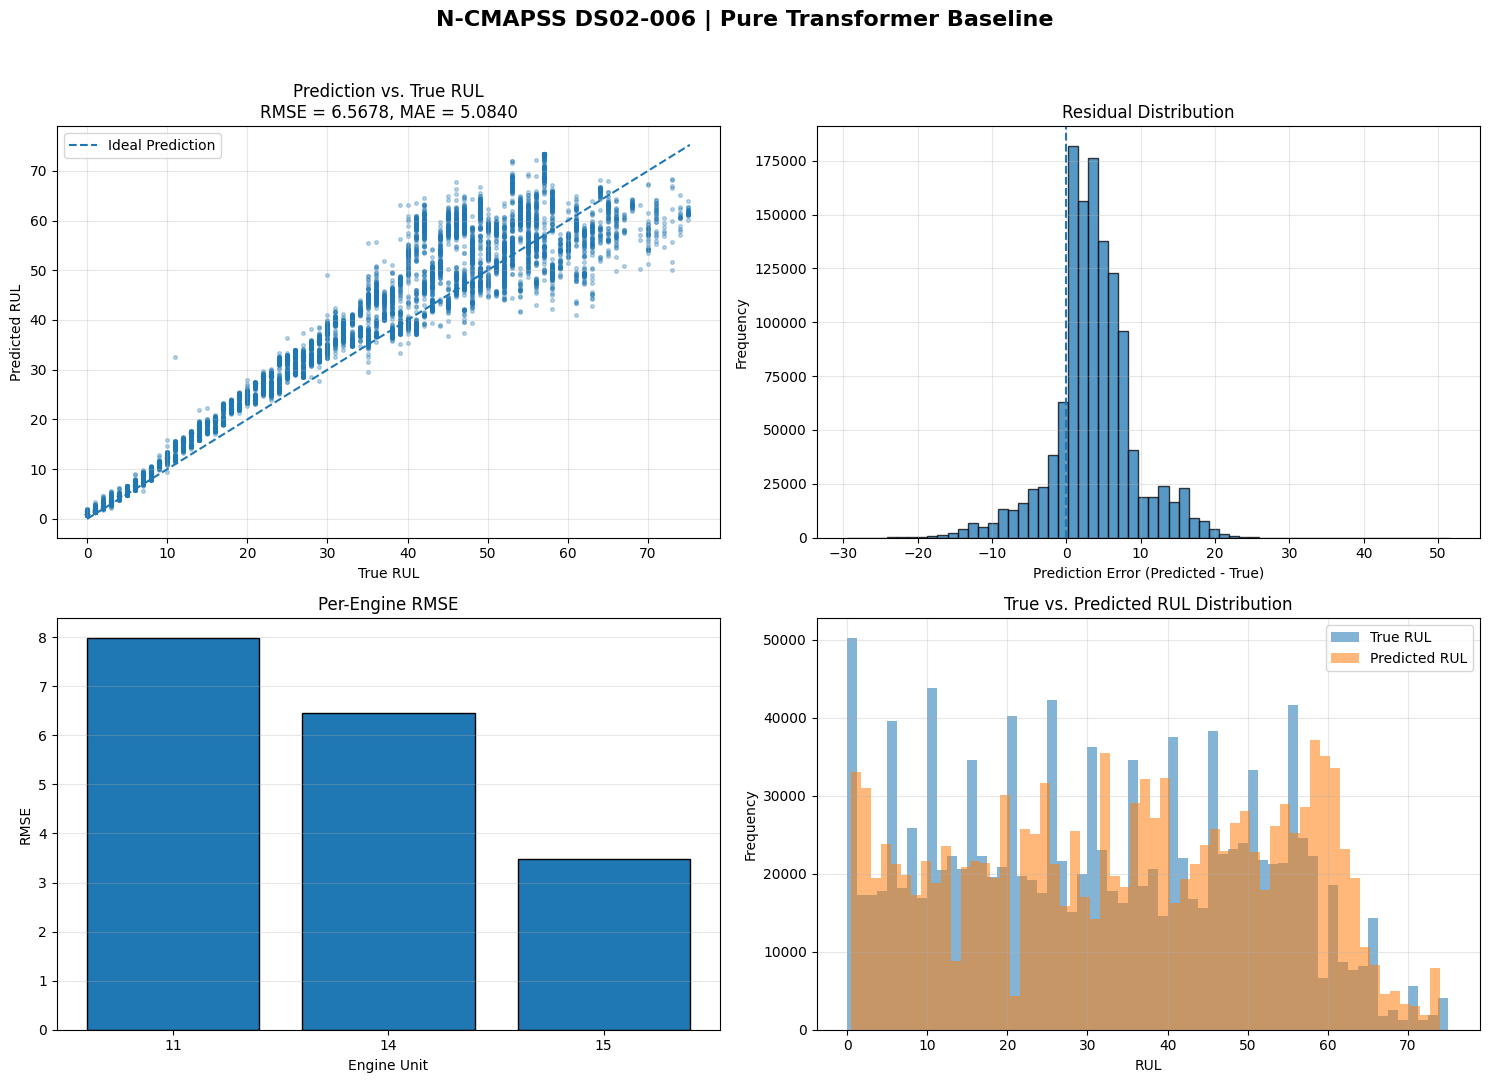


FINAL SUMMARY
Model              : transformer_baseline
Parameters         : 18,913
Best Val MSE       : 83.582660
Test MSE           : 43.135742
Test RMSE          : 6.567781
Test MAE           : 5.084003
Test windows       : 1,253,596
Checkpoint         : best_transformer_baseline.pth
Prediction file    : transformer_baseline_test_predictions.npz
Result figure      : transformer_baseline_test_results.png


In [4]:
# ================================================================
# N-CMAPSS DS02-006 | Pure Transformer Baseline | TEST ONLY
# ================================================================

import os
import math
import h5py
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm


# ================================================================
# 1. Configuration
# ================================================================

SEED = 42

FILE_PATH = 'N-CMAPSS_DS02-006.h5'
MODEL_SAVE_PATH = 'best_transformer_baseline.pth'

MODEL_NAME = 'transformer_baseline'
PREDICTION_SAVE_PATH = 'transformer_baseline_test_predictions.npz'
RESULT_FIG_PATH = 'transformer_baseline_test_results.png'

INPUT_SIZE = 18
BATCH_SIZE = 1024
NUM_WORKERS = 0

DEVICE = torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)


# ================================================================
# 2. Reproducibility
# ================================================================

def set_seed(seed=42):

    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)


# ================================================================
# 3. Load N-CMAPSS test data
# ================================================================

def load_test_data(file_path):

    if not os.path.exists(file_path):
        raise FileNotFoundError(
            f'Cannot find dataset:\n{file_path}\n'
            f'Current working directory:\n{os.getcwd()}'
        )

    with h5py.File(file_path, 'r') as f:

        W_test = f['W_test'][:]
        Xs_test = f['X_s_test'][:]
        A_test = f['A_test'][:]
        Y_test = f['Y_test'][:]

    X_test = np.concatenate(
        [W_test, Xs_test],
        axis=1
    ).astype(np.float32)

    Y_test = np.asarray(
        Y_test,
        dtype=np.float32
    ).reshape(-1)

    units_test = A_test[:, 0].astype(np.int64)

    return X_test, Y_test, units_test


# ================================================================
# 4. Dataset
# ================================================================

class NCMAPSSDataset(Dataset):

    def __init__(
        self,
        X,
        Y,
        unit_array,
        window_size
    ):

        self.X = torch.from_numpy(
            np.asarray(X, dtype=np.float32)
        )

        self.Y = torch.from_numpy(
            np.asarray(Y, dtype=np.float32).reshape(-1, 1)
        )

        self.unit = np.asarray(
            unit_array
        )

        self.window_size = window_size

        starts = []

        for u in np.unique(self.unit):

            idx = np.where(self.unit == u)[0]

            n_valid = max(
                0,
                len(idx) - window_size + 1
            )

            starts.extend(
                idx[:n_valid]
            )

        self.valid_indices = np.asarray(
            starts,
            dtype=np.int64
        )

    def __len__(self):

        return len(self.valid_indices)

    def __getitem__(self, i):

        s = int(self.valid_indices[i])
        e = s + self.window_size

        x = self.X[s:e]
        y = self.Y[e - 1]

        return x, y


# ================================================================
# 5. Positional Encoding
# ================================================================

class PositionalEncoding(nn.Module):

    def __init__(
        self,
        d_model,
        max_len=512
    ):

        super().__init__()

        pe = torch.zeros(
            max_len,
            d_model
        )

        position = torch.arange(
            max_len,
            dtype=torch.float32
        ).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(
                0,
                d_model,
                2,
                dtype=torch.float32
            )
            * (-math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(
            position * div_term
        )

        pe[:, 1::2] = torch.cos(
            position * div_term
        )

        self.register_buffer(
            'pe',
            pe.unsqueeze(0)
        )

    def forward(self, x):

        return (
            x
            + self.pe[:, :x.size(1), :]
        )


# ================================================================
# 6. Transformer Baseline
# ================================================================

class TransformerBaseline(nn.Module):

    def __init__(
        self,
        input_size,
        d_model,
        nhead,
        num_layers,
        dim_feedforward,
        dropout,
        window_size
    ):

        super().__init__()

        if d_model % nhead != 0:
            raise ValueError(
                'd_model must be divisible by nhead.'
            )

        self.input_projection = nn.Sequential(
            nn.Linear(
                input_size,
                d_model
            ),
            nn.LayerNorm(d_model)
        )

        self.pos_encoder = PositionalEncoding(
            d_model,
            window_size
        )

        encoder_layer = (
            nn.TransformerEncoderLayer(
                d_model=d_model,
                nhead=nhead,
                dim_feedforward=dim_feedforward,
                dropout=dropout,
                activation='gelu',
                batch_first=True,
                norm_first=True
            )
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers,
            norm=nn.LayerNorm(d_model)
        )

        self.regressor = nn.Sequential(
            nn.Linear(
                d_model,
                32
            ),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(
                32,
                1
            )
        )

        self._init_weights()

    def _init_weights(self):

        for module in self.modules():

            if isinstance(
                module,
                nn.Linear
            ):

                nn.init.xavier_uniform_(
                    module.weight
                )

                if module.bias is not None:

                    nn.init.zeros_(
                        module.bias
                    )

    def forward(self, x):

        x = self.input_projection(x)

        x = self.pos_encoder(x)

        x = self.encoder(x)

        # Use the last timestep
        x = x[:, -1, :]

        return self.regressor(x)


# ================================================================
# 7. Metrics
# ================================================================

def mse_np(pred, true):

    pred = np.asarray(pred).reshape(-1)
    true = np.asarray(true).reshape(-1)

    return float(
        np.mean(
            (pred - true) ** 2
        )
    )


def rmse_np(pred, true):

    return float(
        np.sqrt(
            mse_np(pred, true)
        )
    )


def mae_np(pred, true):

    pred = np.asarray(pred).reshape(-1)
    true = np.asarray(true).reshape(-1)

    return float(
        np.mean(
            np.abs(pred - true)
        )
    )


# ================================================================
# 8. Main TEST procedure
# ================================================================

print('=' * 72)
print('N-CMAPSS DS02-006 | Pure Transformer Baseline | TEST ONLY')
print('=' * 72)

print('Device:', DEVICE)

if torch.cuda.is_available():

    print(
        'GPU:',
        torch.cuda.get_device_name(0)
    )


# ------------------------------------------------
# Check checkpoint
# ------------------------------------------------

if not os.path.exists(
    MODEL_SAVE_PATH
):

    raise FileNotFoundError(
        f'Checkpoint not found:\n'
        f'{MODEL_SAVE_PATH}\n\n'
        f'Please run the training cell first.'
    )


print(
    'Checkpoint:',
    MODEL_SAVE_PATH
)


# ================================================================
# 9. Load test data
# ================================================================

X_test, Y_test, units_test = load_test_data(
    FILE_PATH
)

print()
print('Test raw data:')
print(
    'X_test shape:',
    X_test.shape
)

print(
    'Y_test shape:',
    Y_test.shape
)

print(
    'Test engines:',
    np.unique(units_test)
)


# ================================================================
# 10. Load checkpoint
# ================================================================

print()
print('Loading checkpoint...')


# PyTorch 2.6 compatibility:
# The checkpoint contains numpy scaler information,
# therefore weights_only=False is required here.
checkpoint = torch.load(
    MODEL_SAVE_PATH,
    map_location=DEVICE,
    weights_only=False
)


print('Checkpoint loaded.')


# ================================================================
# 11. Restore model configuration
# ================================================================

D_MODEL = checkpoint['d_model']
N_HEAD = checkpoint['nhead']
N_LAYERS = checkpoint['num_layers']
DIM_FEEDFORWARD = checkpoint['dim_feedforward']
DROPOUT = checkpoint['dropout']
WINDOW_SIZE = checkpoint['window_size']

BEST_VAL_MSE = checkpoint.get(
    'best_val_loss',
    np.nan
)

print()
print('Checkpoint information:')
print(
    f'Best Val MSE : {BEST_VAL_MSE:.6f}'
)

print(
    f'D_MODEL      : {D_MODEL}'
)

print(
    f'N_HEAD       : {N_HEAD}'
)

print(
    f'N_LAYERS     : {N_LAYERS}'
)

print(
    f'FF DIM       : {DIM_FEEDFORWARD}'
)

print(
    f'DROPOUT      : {DROPOUT}'
)

print(
    f'WINDOW SIZE  : {WINDOW_SIZE}'
)


# ================================================================
# 12. Restore scaler
# ================================================================

x_min = np.asarray(
    checkpoint['x_min'],
    dtype=np.float32
)

x_max = np.asarray(
    checkpoint['x_max'],
    dtype=np.float32
)

denominator = np.where(
    x_max - x_min < 1e-8,
    1.0,
    x_max - x_min
)

X_test_scaled = (
    2.0
    * (X_test - x_min)
    / denominator
    - 1.0
).astype(np.float32)


print()
print('Scaler restored.')

print(
    'Scaled test range: '
    f'min={X_test_scaled.min():.6f}, '
    f'max={X_test_scaled.max():.6f}'
)


# ================================================================
# 13. Build test dataset
# ================================================================

test_dataset = NCMAPSSDataset(
    X_test_scaled,
    Y_test,
    units_test,
    WINDOW_SIZE
)

print(
    f'Test windows: '
    f'{len(test_dataset):,}'
)


test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)


# ================================================================
# 14. Build model
# ================================================================

model = TransformerBaseline(
    input_size=INPUT_SIZE,
    d_model=D_MODEL,
    nhead=N_HEAD,
    num_layers=N_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT,
    window_size=WINDOW_SIZE
).to(DEVICE)


# ================================================================
# 15. Load model weights
# ================================================================

model.load_state_dict(
    checkpoint['model_state_dict']
)

model.eval()


trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print()
print('Model loaded successfully.')

print(
    'Trainable parameters:',
    f'{trainable_params:,}'
)


# ================================================================
# 16. Prediction
# ================================================================

print()
print('Running test prediction...')

predictions = []
targets = []

with torch.no_grad():

    for xb, yb in tqdm(
        test_loader,
        desc='Testing',
        ncols=100
    ):

        xb = xb.to(
            DEVICE,
            non_blocking=True
        )

        output = model(xb)

        predictions.append(
            output.cpu().numpy()
        )

        targets.append(
            yb.numpy()
        )


predictions = np.concatenate(
    predictions
).reshape(-1)

targets = np.concatenate(
    targets
).reshape(-1)


# ================================================================
# 17. Overall metrics
# ================================================================

mse = mse_np(
    predictions,
    targets
)

rmse = rmse_np(
    predictions,
    targets
)

mae = mae_np(
    predictions,
    targets
)


print()
print('=' * 72)
print('OVERALL TEST RESULT')
print('=' * 72)

print(
    f'Test MSE  : {mse:.6f}'
)

print(
    f'Test RMSE : {rmse:.6f}'
)

print(
    f'Test MAE  : {mae:.6f}'
)

print(
    f'Test N    : {len(targets):,}'
)


# ================================================================
# 18. Per-engine metrics
# ================================================================

window_units = np.array(
    [
        units_test[int(s)]
        for s in test_dataset.valid_indices
    ]
)

unique_units = np.unique(
    window_units
)

unit_rmse = []
unit_mae = []
unit_mse = []
unit_count = []

print()
print('=' * 72)
print('PER-ENGINE TEST RESULT')
print('=' * 72)

for unit in unique_units:

    mask = window_units == unit

    p = predictions[mask]
    y = targets[mask]

    u_mse = mse_np(p, y)
    u_rmse = rmse_np(p, y)
    u_mae = mae_np(p, y)

    unit_mse.append(u_mse)
    unit_rmse.append(u_rmse)
    unit_mae.append(u_mae)
    unit_count.append(
        int(mask.sum())
    )

    print(
        f'Unit {int(unit):3d} | '
        f'MSE={u_mse:.6f} | '
        f'RMSE={u_rmse:.6f} | '
        f'MAE={u_mae:.6f} | '
        f'N={int(mask.sum()):,}'
    )


# ================================================================
# 19. Save predictions
# ================================================================

np.savez(
    PREDICTION_SAVE_PATH,
    predictions=predictions,
    targets=targets,
    units=window_units
)

print()
print(
    'Prediction file saved:',
    PREDICTION_SAVE_PATH
)


# ================================================================
# 20. Visualization
# ================================================================

print()
print('Generating English visualization...')


fig = plt.figure(
    figsize=(15, 11)
)


# ------------------------------------------------
# Plot 1: Prediction vs Truth
# ------------------------------------------------

ax1 = fig.add_subplot(2, 2, 1)

rng = np.random.default_rng(
    SEED
)

N_SAMPLE = min(
    10000,
    len(predictions)
)

sample_ids = rng.choice(
    len(predictions),
    size=N_SAMPLE,
    replace=False
)

ax1.scatter(
    targets[sample_ids],
    predictions[sample_ids],
    s=7,
    alpha=0.30
)

lo = min(
    targets.min(),
    predictions.min()
)

hi = max(
    targets.max(),
    predictions.max()
)

ax1.plot(
    [lo, hi],
    [lo, hi],
    '--',
    linewidth=1.5,
    label='Ideal Prediction'
)

ax1.set_xlabel(
    'True RUL'
)

ax1.set_ylabel(
    'Predicted RUL'
)

ax1.set_title(
    f'Prediction vs. True RUL\n'
    f'RMSE = {rmse:.4f}, MAE = {mae:.4f}'
)

ax1.legend()
ax1.grid(
    alpha=0.3
)


# ------------------------------------------------
# Plot 2: Residual Distribution
# ------------------------------------------------

ax2 = fig.add_subplot(2, 2, 2)

residuals = (
    predictions
    - targets
)

ax2.hist(
    residuals,
    bins=60,
    alpha=0.75,
    edgecolor='black'
)

ax2.axvline(
    0,
    linestyle='--',
    linewidth=1.5
)

ax2.set_xlabel(
    'Prediction Error (Predicted - True)'
)

ax2.set_ylabel(
    'Frequency'
)

ax2.set_title(
    'Residual Distribution'
)

ax2.grid(
    alpha=0.3
)


# ------------------------------------------------
# Plot 3: Per-engine RMSE
# ------------------------------------------------

ax3 = fig.add_subplot(2, 2, 3)

engine_labels = [
    str(int(u))
    for u in unique_units
]

ax3.bar(
    engine_labels,
    unit_rmse,
    edgecolor='black'
)

ax3.set_xlabel(
    'Engine Unit'
)

ax3.set_ylabel(
    'RMSE'
)

ax3.set_title(
    'Per-Engine RMSE'
)

ax3.grid(
    axis='y',
    alpha=0.3
)


# ------------------------------------------------
# Plot 4: True vs Predicted RUL Distribution
# ------------------------------------------------

ax4 = fig.add_subplot(2, 2, 4)

ax4.hist(
    targets,
    bins=60,
    alpha=0.55,
    label='True RUL'
)

ax4.hist(
    predictions,
    bins=60,
    alpha=0.55,
    label='Predicted RUL'
)

ax4.set_xlabel(
    'RUL'
)

ax4.set_ylabel(
    'Frequency'
)

ax4.set_title(
    'True vs. Predicted RUL Distribution'
)

ax4.legend()

ax4.grid(
    alpha=0.3
)


# ------------------------------------------------
# Save figure
# ------------------------------------------------

plt.suptitle(
    'N-CMAPSS DS02-006 | Pure Transformer Baseline',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.savefig(
    RESULT_FIG_PATH,
    dpi=200,
    bbox_inches='tight'
)

plt.show()


# ================================================================
# 21. Final summary
# ================================================================

print()
print('=' * 72)
print('FINAL SUMMARY')
print('=' * 72)

print(
    f'Model              : '
    f'{MODEL_NAME}'
)

print(
    f'Parameters         : '
    f'{trainable_params:,}'
)

print(
    f'Best Val MSE       : '
    f'{BEST_VAL_MSE:.6f}'
)

print(
    f'Test MSE           : '
    f'{mse:.6f}'
)

print(
    f'Test RMSE          : '
    f'{rmse:.6f}'
)

print(
    f'Test MAE           : '
    f'{mae:.6f}'
)

print(
    f'Test windows       : '
    f'{len(targets):,}'
)

print(
    f'Checkpoint         : '
    f'{MODEL_SAVE_PATH}'
)

print(
    f'Prediction file    : '
    f'{PREDICTION_SAVE_PATH}'
)

print(
    f'Result figure      : '
    f'{RESULT_FIG_PATH}'
)

print('=' * 72)